In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ss'
organism = 'mouse-2019-stringer'

In [4]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

In [5]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

# scores

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
boms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)[0] for filename in filenames]
hgms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)[0] for filename in filenames]

In [8]:
neuron_scores = assemble(boms_spn, hgms_spn)

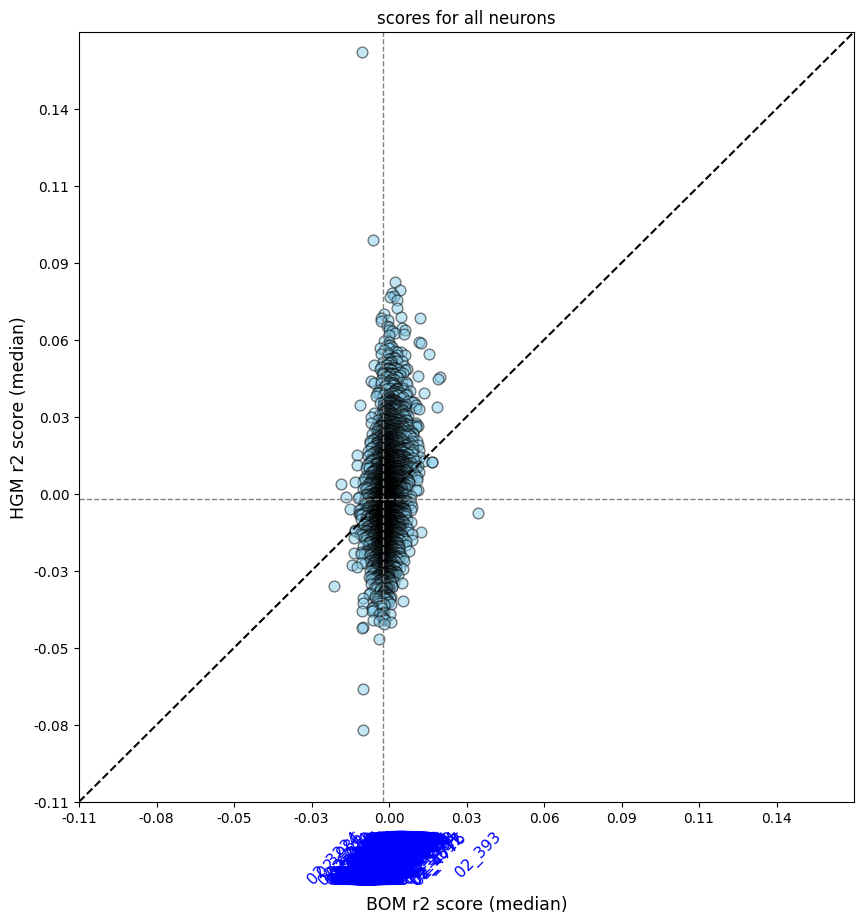

In [10]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.11, 0.17, -0.11, 0.17), force_medians=False
)

In [10]:
neuron_scores_hgm_rel = list(reversed(sorted({key: value for key, value in neuron_scores.items() if 0 < np.median(value[0]) < np.median(value[1])}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_rel_labels = list([val[0] for val in neuron_scores_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_rel]))

NEURON: 02_8146,		HGMSCR: 0.0788
NEURON: 02_233,		HGMSCR: 0.0761
NEURON: 02_2174,		HGMSCR: 0.0749
NEURON: 02_7412,		HGMSCR: 0.0739
NEURON: 02_7204,		HGMSCR: 0.0736
NEURON: 02_2214,		HGMSCR: 0.0726
NEURON: 02_7331,		HGMSCR: 0.0696
NEURON: 02_8097,		HGMSCR: 0.0672
NEURON: 02_030,		HGMSCR: 0.0664
NEURON: 02_3761,		HGMSCR: 0.0659
NEURON: 02_1408,		HGMSCR: 0.0651
NEURON: 02_1246,		HGMSCR: 0.0630
NEURON: 02_1107,		HGMSCR: 0.0628
NEURON: 02_4429,		HGMSCR: 0.0623
NEURON: 02_5477,		HGMSCR: 0.0615
NEURON: 02_130,		HGMSCR: 0.0615
NEURON: 02_5545,		HGMSCR: 0.0612
NEURON: 02_6505,		HGMSCR: 0.0606
NEURON: 02_086,		HGMSCR: 0.0600
NEURON: 02_6212,		HGMSCR: 0.0596
NEURON: 02_1327,		HGMSCR: 0.0577
NEURON: 02_2099,		HGMSCR: 0.0572
NEURON: 02_1200,		HGMSCR: 0.0571
NEURON: 02_3997,		HGMSCR: 0.0570
NEURON: 02_6502,		HGMSCR: 0.0561
NEURON: 02_6449,		HGMSCR: 0.0560
NEURON: 02_5548,		HGMSCR: 0.0553
NEURON: 02_8195,		HGMSCR: 0.0552
NEURON: 02_6246,		HGMSCR: 0.0541
NEURON: 02_1321,		HGMSCR: 0.0540
NEURON: 02_023

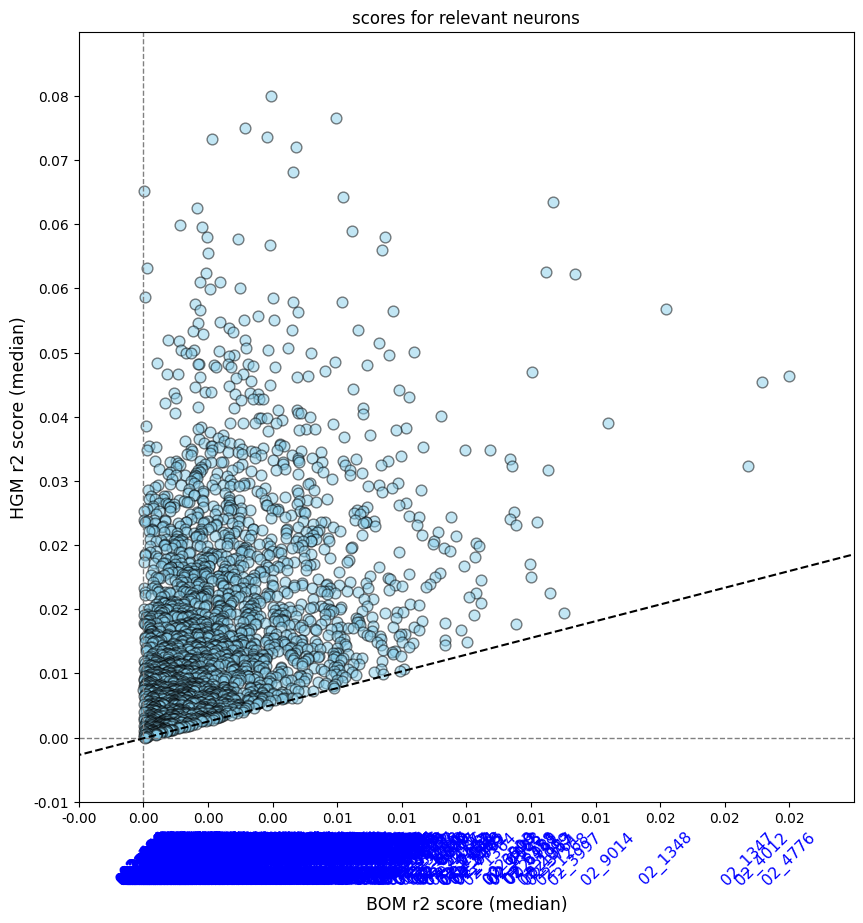

In [11]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='scores for relevant neurons', limits=None, force_medians=False
)

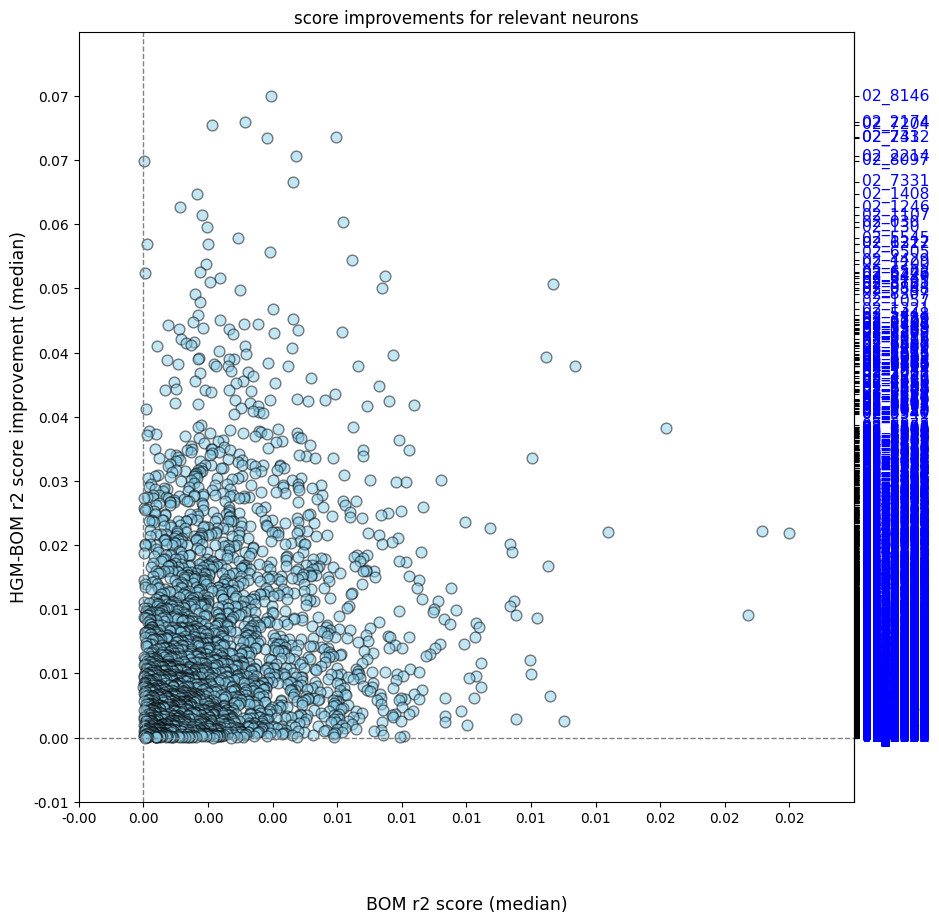

In [12]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='score improvements for relevant neurons', limits=None, force_medians=False
)

In [13]:
neuron_impros_hgm_rel = list(reversed(sorted(neuron_scores_hgm_rel, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_rel]))

NEURON: 02_8146,		IMPR: 0.0748
NEURON: 02_2174,		IMPR: 0.0717
NEURON: 02_7204,		IMPR: 0.0714
NEURON: 02_233,		IMPR: 0.0700
NEURON: 02_7412,		IMPR: 0.0699
NEURON: 02_2214,		IMPR: 0.0678
NEURON: 02_8097,		IMPR: 0.0672
NEURON: 02_7331,		IMPR: 0.0648
NEURON: 02_1408,		IMPR: 0.0634
NEURON: 02_1246,		IMPR: 0.0618
NEURON: 02_1107,		IMPR: 0.0609
NEURON: 02_030,		IMPR: 0.0601
NEURON: 02_130,		IMPR: 0.0595
NEURON: 02_5545,		IMPR: 0.0582
NEURON: 02_6212,		IMPR: 0.0576
NEURON: 02_1327,		IMPR: 0.0576
NEURON: 02_6505,		IMPR: 0.0566
NEURON: 02_4429,		IMPR: 0.0557
NEURON: 02_1200,		IMPR: 0.0552
NEURON: 02_6502,		IMPR: 0.0543
NEURON: 02_6246,		IMPR: 0.0541
NEURON: 02_5477,		IMPR: 0.0539
NEURON: 02_6449,		IMPR: 0.0536
NEURON: 02_8195,		IMPR: 0.0531
NEURON: 02_3761,		IMPR: 0.0529
NEURON: 02_086,		IMPR: 0.0524
NEURON: 02_5548,		IMPR: 0.0522
NEURON: 02_8307,		IMPR: 0.0517
NEURON: 02_1057,		IMPR: 0.0508
NEURON: 02_1321,		IMPR: 0.0499
NEURON: 02_5448,		IMPR: 0.0493
NEURON: 02_3736,		IMPR: 0.0488
NEURON: 02_7

In [14]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels]))

Neuron names for copying:
'02_8146', '02_2174', '02_7204', '02_233', '02_7412', '02_2214', '02_8097', '02_7331', '02_1408', '02_1246', '02_1107', '02_030', '02_130', '02_5545', '02_6212', '02_1327', '02_6505', '02_4429', '02_1200', '02_6502', '02_6246', '02_5477', '02_6449', '02_8195', '02_3761', '02_086', '02_5548', '02_8307', '02_1057', '02_1321', '02_5448', '02_3736', '02_7829', '02_6203', '02_2101', '02_8167', '02_7446', '02_5309', '02_7249', '02_236', '02_7355', '02_023', '02_7309', '02_3368', '02_9016', '02_7398', '02_8317', '02_6801', '02_9002', '02_5486', '02_3269', '02_880', '02_2011', '02_1545', '02_2099', '02_5508', '02_1062', '02_306', '02_1042', '02_058', '02_7525', '02_5483', '02_6586', '02_974', '02_6601', '02_3997', '02_7490', '02_5550', '02_7244', '02_355', '02_1027', '02_3993', '02_4740', '02_8511', '02_462', '02_7260', '02_2068', '02_1189', '02_2265', '02_5762', '02_3094', '02_8288', '02_6546', '02_7405', '02_1270', '02_5567', '02_8230', '02_3973', '02_8242', '02_756